# CBIS-DDSM Dataset Audit and Patient-Grouped Split

This notebook audits the CBIS-DDSM mass-training metadata, resolves duplicate and conflicting mammogram records, recovers patient identifiers, and creates reproducible patient-independent training and validation manifests for the subsequent baseline CNN and VGG16 experiments.

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

DATASET_DIR = os.environ.get(
    "CBIS_DDSM_DIR",
    os.path.join("..", "data", "CBIS-DDSM")
)

CSV_DIR = os.path.join(DATASET_DIR, "csv")
JPEG_DIR = os.path.join(DATASET_DIR, "jpeg")

print("CSV folder exists:", os.path.exists(CSV_DIR))
print("JPEG folder exists:", os.path.exists(JPEG_DIR))
print("CSV files:", os.listdir(CSV_DIR))

CSV folder exists: True
JPEG folder exists: True
CSV files: ['calc_case_description_test_set.csv', 'calc_case_description_train_set.csv', 'dicom_info.csv', 'mass_case_description_test_set.csv', 'mass_case_description_train_set.csv', 'meta.csv']


In [4]:
train_mass = pd.read_csv(
    os.path.join(CSV_DIR, "mass_case_description_train_set.csv")
)

print("Rows:", len(train_mass))
print("\nColumns:")
print(train_mass.columns.tolist())

Rows: 1318

Columns:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


In [5]:
print(train_mass["pathology"].value_counts())

pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64


In [6]:
train_mass["label"] = train_mass["pathology"].apply(
    lambda x: 1 if x == "MALIGNANT" else 0
)

print(train_mass[["pathology", "label"]].head())
print("\nBinary label distribution:")
print(train_mass["label"].value_counts())

   pathology  label
0  MALIGNANT      1
1  MALIGNANT      1
2     BENIGN      0
3     BENIGN      0
4     BENIGN      0

Binary label distribution:
label
0    681
1    637
Name: count, dtype: int64


The pathology labels were converted into binary classes, where malignant cases were assigned a label of 1 and benign cases (including benign without callback) were assigned a label of 0. The resulting dataset contained 637 malignant samples and 681 benign samples, indicating a relatively balanced class distribution suitable for supervised learning.

In [7]:
print(train_mass["image file path"].iloc[0])

Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm


In [8]:
for root, dirs, files in os.walk(JPEG_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))

    if len(files) > 0:
        print("First 5 files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg
Number of files: 0
Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Number of files: 2
First 5 files: ['1-263.jpg', '2-241.jpg']


In [9]:
dicom_info = pd.read_csv(os.path.join(CSV_DIR, "dicom_info.csv"))

print("Rows:", len(dicom_info))
print("\nColumns:")
print(dicom_info.columns.tolist())

print("\nFirst 3 rows:")
display(dicom_info.head(3))

Rows: 10237

Columns:
['file_path', 'image_path', 'AccessionNumber', 'BitsAllocated', 'BitsStored', 'BodyPartExamined', 'Columns', 'ContentDate', 'ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber', 'LargestImagePixelValue', 'Laterality', 'Modality', 'PatientBirthDate', 'PatientID', 'PatientName', 'PatientOrientation', 'PatientSex', 'PhotometricInterpretation', 'PixelRepresentation', 'ReferringPhysicianName', 'Rows', 'SOPClassUID', 'SOPInstanceUID', 'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer', 'SecondaryCaptureDeviceManufacturerModelName', 'SeriesDescription', 'SeriesInstanceUID', 'SeriesNumber', 'SmallestImagePixelValue', 'SpecificCharacterSet', 'StudyDate', 'StudyID', 'StudyInstanceUID', 'StudyTime']

First 3 rows:


,file_path,image_path,AccessionNumber,BitsAllocated,BitsStored,BodyPartExamined,Columns,ContentDate,ContentTime,ConversionType,...,SecondaryCaptureDeviceManufacturerModelName,SeriesDescription,SeriesInstanceUID,SeriesNumber,SmallestImagePixelValue,SpecificCharacterSet,StudyDate,StudyID,StudyInstanceUID,StudyTime
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,NaN,16,16,BREAST,351,20160426,131732.685,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.129308726812851964007...,1,23078,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.271867287611061855725...,214951.0
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,NaN,16,16,BREAST,3526,20160426,143829.101,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.248386742010678582309...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.161516517311681906612...,193426.0
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,NaN,16,16,BREAST,1546,20160503,111956.298,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.267213171011171858918...,1,0,ISO_IR 100,20160807.0,DDSM,1.3.6.1.4.1.9590.100.1.2.291043622711253836701...,161814.0


In [10]:
dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.15333...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.15333...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.17899...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.17899...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.41183...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...,ROI mask images


In [11]:
pd.set_option("display.max_colwidth", None)

display(
    dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)
)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.jpg,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.jpg,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.jpg,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.jpg,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.jpg,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.jpg,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.jpg,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.jpg,ROI mask images


In [12]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Number of full mammograms:", len(full_mammo))

display(
    full_mammo[["image_path"]].head(5)
)

Number of full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
Exists: True


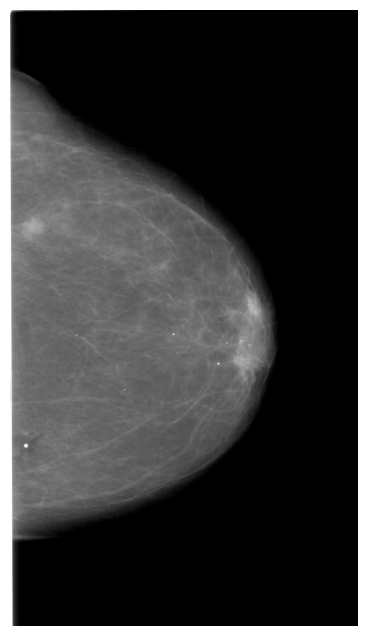

Image size: (3526, 6256)


In [13]:
sample_path = r"CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg"

full_path = os.path.join(
    DATASET_DIR,
    sample_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
)

print(full_path)
print("Exists:", os.path.exists(full_path))

img = Image.open(full_path)

plt.figure(figsize=(8,8))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

print("Image size:", img.size)

In [14]:
sizes = []

for root, dirs, files in os.walk(JPEG_DIR):
    for file in files:
        if file.endswith(".jpg"):
            path = os.path.join(root, file)

            try:
                img = Image.open(path)
                sizes.append(img.size)
            except:
                pass

            if len(sizes) >= 100:
                break

    if len(sizes) >= 100:
        break

print("First 10 image sizes:")
print(sizes[:10])

print("\nUnique sizes found:")
print(set(sizes))

First 10 image sizes:
[(226, 211), (2626, 5056), (3826, 6601), (4126, 5491), (3151, 5491), (89, 81), (4072, 5728), (2952, 4504), (3480, 5992), (2568, 4648)]

Unique sizes found:
{(497, 537), (3056, 4528), (2912, 4544), (2626, 4996), (3096, 4664), (3904, 5640), (3360, 5912), (370, 327), (453, 407), (2568, 4648), (3416, 6032), (262, 247), (305, 401), (265, 209), (553, 441), (226, 211), (438, 448), (292, 229), (756, 913), (3048, 4576), (436, 386), (2807, 4595), (2888, 4504), (3151, 5491), (2506, 4741), (249, 233), (417, 409), (2992, 4616), (4081, 6691), (3544, 6032), (449, 459), (2281, 5296), (2926, 5491), (2904, 4176), (3968, 5712), (2491, 5206), (2616, 4712), (3072, 4544), (129, 145), (2896, 4672), (761, 785), (289, 225), (2731, 5236), (4426, 6511), (89, 81), (4024, 5704), (191, 266), (3280, 5896), (3136, 6526), (2566, 5296), (3712, 5584), (1846, 4006), (304, 310), (273, 249), (2952, 4504), (2512, 4760), (4136, 5840), (4126, 5491), (2341, 5326), (2664, 4720), (3992, 5768), (2911, 5491),

In [15]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammogram rows:", len(full_mammo))

sizes = []

for _, row in full_mammo.head(100).iterrows():

    img_path = row["image_path"]

    img_path = img_path.replace(
        "CBIS-DDSM/jpeg/",
        "jpeg/"
    )

    full_path = os.path.join(DATASET_DIR, img_path)

    try:
        img = Image.open(full_path)
        sizes.append(img.size)
    except:
        pass

print("Unique sizes among first 100 full mammograms:")
print(set(sizes))

Full mammogram rows: 2857
Unique sizes among first 100 full mammograms:
{(3056, 4464), (2456, 4704), (3136, 4664), (2056, 5041), (2840, 4632), (3704, 5704), (2824, 4696), (1981, 4876), (2864, 4424), (2912, 4592), (3496, 5491), (2960, 4712), (2712, 4784), (2664, 4744), (4501, 6871), (2808, 4544), (3008, 4480), (3080, 4560), (2671, 5896), (3032, 4520), (3136, 4696), (1872, 4736), (4040, 5648), (3631, 6706), (3128, 4728), (2851, 5011), (4256, 6032), (3481, 5971), (4056, 5768), (2941, 5221), (2888, 4568), (2432, 4672), (2926, 5491), (3088, 4760), (3112, 4824), (3466, 5386), (2472, 4720), (3224, 5944), (2728, 4752), (3256, 5976), (2371, 5491), (3886, 6271), (3104, 4624), (2896, 4528), (3040, 4496), (2728, 4736), (2936, 4448), (3528, 5976), (2712, 4712), (3091, 6676), (4048, 5752), (2840, 4672), (3048, 5912), (3526, 6256), (3106, 6466), (2624, 4608), (4072, 5920), (4306, 6871), (3361, 5206), (3720, 5752), (4088, 5864), (4048, 5864), (2911, 5491), (2326, 5356), (2752, 4680), (2784, 4568), (35

## Image Resizing Rationale

All mammograms were resized to 224 x 224 pixels to provide a consistent input size and reduce computational requirements during model training. This resolution was also retained across the baseline CNN and VGG16 experiments so that both models used the same spatial input dimensions.

In [16]:
print(train_mass.columns.tolist())

['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path', 'label']


In [17]:
train_mass[[
    "image file path",
    "label"
]].head()

,image file path,label
0,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm,1
1,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm,1
2,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.347107867812656628709864319310977895697/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/000000.dcm,0
3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.272600286511817402806912403581910920939/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/000000.dcm,0
4,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.174047308712169195014610267031196524486/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/000000.dcm,0


In [18]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammograms:", len(full_mammo))

full_mammo[["image_path"]].head()

Full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


In [19]:
print(full_mammo["image_path"].iloc[0])

CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg


In [20]:
meta = pd.read_csv(
    os.path.join(CSV_DIR, "meta.csv")
)

print(meta.head())
print("\n")
print(meta.columns.tolist())

                                                  SeriesInstanceUID  \
0  1.3.6.1.4.1.9590.100.1.2.117041576511324414842508325652101471266   
1   1.3.6.1.4.1.9590.100.1.2.43873839610761788013224723323225482381   
2   1.3.6.1.4.1.9590.100.1.2.76741674113167646338262765132488965294   
3  1.3.6.1.4.1.9590.100.1.2.296931352612305599800425693833437698626   
4   1.3.6.1.4.1.9590.100.1.2.43665767012035310007732414810147712942   

                                                   StudyInstanceUID Modality  \
0  1.3.6.1.4.1.9590.100.1.2.229361142710768138411679379233064924540       MG   
1  1.3.6.1.4.1.9590.100.1.2.195593486612988388325770883972107282733       MG   
2  1.3.6.1.4.1.9590.100.1.2.257901172612530623323924356380431605062       MG   
3  1.3.6.1.4.1.9590.100.1.2.109468616710242115222536802734027827120       MG   
4  1.3.6.1.4.1.9590.100.1.2.380627129513562450304304820723973964760       MG   

  SeriesDescription BodyPartExamined  SeriesNumber Collection  Visibility  \
0   ROI mask im

In [21]:
for root, dirs, files in os.walk(JPEG_DIR):
    if files:
        print("Folder:", root)
        print("Files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Files: ['1-263.jpg', '2-241.jpg']


In [22]:
sample_folder = os.path.join(
    JPEG_DIR,
    os.listdir(JPEG_DIR)[0]
)

print("Sample folder:")
print(sample_folder)

print("\nFiles inside:")
print(os.listdir(sample_folder))

Sample folder:
C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132

Files inside:
['1-263.jpg', '2-241.jpg']


In [23]:
print(train_mass["image file path"].iloc[0])

Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm


In [24]:
print(train_mass["image file path"].iloc[1])

Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm


In [25]:
uid = "1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515"

matches = dicom_info[
    dicom_info["image_path"].str.contains(uid, na=False)
]

print("Matches found:", len(matches))

if len(matches) > 0:
    display(matches[[
        "image_path",
        "SeriesDescription"
    ]].head())

Matches found: 1


,image_path,SeriesDescription
7774,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,full mammogram images


In [26]:
def get_jpeg_path_from_dicom_path(dicom_path):
    parts = dicom_path.split("/")
    
    # The second UID folder maps to the JPEG image in dicom_info
    target_uid = parts[-2]
    
    matches = dicom_info[
        dicom_info["image_path"].str.contains(target_uid, na=False)
    ]
    
    # Prefer full mammogram images
    matches = matches[
        matches["SeriesDescription"] == "full mammogram images"
    ]
    
    if len(matches) == 0:
        return None
    
    jpeg_relative_path = matches.iloc[0]["image_path"]
    jpeg_relative_path = jpeg_relative_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
    
    return os.path.join(DATASET_DIR, jpeg_relative_path)

In [27]:
test_path = get_jpeg_path_from_dicom_path(
    train_mass["image file path"].iloc[0]
)

print(test_path)
print("Exists:", os.path.exists(test_path))
print("Label:", train_mass["label"].iloc[0])

C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg
Exists: True
Label: 1


In [28]:
train_mass["jpeg_path"] = train_mass["image file path"].apply(
    get_jpeg_path_from_dicom_path
)

print("Total rows:", len(train_mass))
print("Rows with valid JPEG paths:", train_mass["jpeg_path"].notna().sum())
print("Rows missing JPEG paths:", train_mass["jpeg_path"].isna().sum())

train_dataset = train_mass[
    train_mass["jpeg_path"].notna()
][["jpeg_path", "label", "pathology"]].copy()

display(train_dataset.head())

Total rows: 1318
Rows with valid JPEG paths: 1318
Rows missing JPEG paths: 0


,jpeg_path,label,pathology
0,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,1,MALIGNANT
1,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg,1,MALIGNANT
2,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg,0,BENIGN
3,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg,0,BENIGN
4,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg,0,BENIGN


In [29]:
print(train_dataset.shape)
print(train_dataset.columns.tolist())
train_dataset.head()

(1318, 3)
['jpeg_path', 'label', 'pathology']


,jpeg_path,label,pathology
0,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,1,MALIGNANT
1,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg,1,MALIGNANT
2,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg,0,BENIGN
3,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg,0,BENIGN
4,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg,0,BENIGN


## Audit duplicate image paths and conflicting labels

The source CSV describes abnormalities rather than guaranteeing one independent row per full mammogram. This step checks how many metadata rows map to the same image and whether any identical full mammograms have conflicting binary labels.

In [30]:
image_audit = (
    train_dataset
    .groupby("jpeg_path")
    .agg(
        row_count=("jpeg_path", "size"),
        unique_labels=("label", "nunique"),
        labels=("label", lambda x: sorted(x.unique().tolist())),
        pathologies=("pathology", lambda x: sorted(x.unique().tolist()))
    )
    .reset_index()
)

duplicate_images = image_audit[image_audit["row_count"] > 1]
conflicting_images = image_audit[image_audit["unique_labels"] > 1]

print("Total metadata rows:", len(train_dataset))
print("Unique full mammograms:", train_dataset["jpeg_path"].nunique())
print("Image paths appearing more than once:", len(duplicate_images))
print("Image paths with conflicting binary labels:", len(conflicting_images))

conflicting_images

Total metadata rows: 1318
Unique full mammograms: 1231
Image paths appearing more than once: 58
Image paths with conflicting binary labels: 6


,jpeg_path,row_count,unique_labels,labels,pathologies
173,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.154877164112814387839246109501067006440/1-231.jpg,3,2,"[0, 1]","[BENIGN, MALIGNANT]"
220,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.168142052011948789309937030612218988654/1-068.jpg,3,2,"[0, 1]","[BENIGN, MALIGNANT]"
252,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.175043772610570804328930190413021504082/1-133.jpg,2,2,"[0, 1]","[BENIGN, MALIGNANT]"
628,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.290000938812700402005626187593866319925/1-213.jpg,2,2,"[0, 1]","[BENIGN, MALIGNANT]"
732,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.328977677511962475112321192060403830590/1-242.jpg,2,2,"[0, 1]","[BENIGN, MALIGNANT]"
1147,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.72724605212412925123701405661626433580/1-119.jpg,2,2,"[0, 1]","[BENIGN, MALIGNANT]"


## Create an image-level dataset

Full mammograms with conflicting binary labels are excluded because one identical input cannot be assigned two different target labels. The remaining records are deduplicated so that each full mammogram appears exactly once.

In [31]:
conflicting_paths = set(conflicting_images["jpeg_path"])

clean_image_dataset = (
    train_dataset[~train_dataset["jpeg_path"].isin(conflicting_paths)]
    .drop_duplicates(subset=["jpeg_path"])
    .reset_index(drop=True)
)

print("Original metadata rows:", len(train_dataset))
print("Excluded conflicting mammograms:", len(conflicting_paths))
print("Clean unique mammograms:", len(clean_image_dataset))
print("Remaining duplicate image paths:",
      clean_image_dataset["jpeg_path"].duplicated().sum())

print("\nLabel distribution:")
print(clean_image_dataset["label"].value_counts())

Original metadata rows: 1318
Excluded conflicting mammograms: 6
Clean unique mammograms: 1225
Remaining duplicate image paths: 0

Label distribution:
label
0    629
1    596
Name: count, dtype: int64


## Recover patient identifiers

A patient identifier is required so that all mammograms belonging to the same patient are assigned to only one dataset partition. This prevents patient-level information leakage between training and validation data.

In [32]:
print("Available dataframes and columns:\n")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, "->", obj.columns.tolist())

Available dataframes and columns:

train_mass -> ['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path', 'label', 'jpeg_path']
dicom_info -> ['file_path', 'image_path', 'AccessionNumber', 'BitsAllocated', 'BitsStored', 'BodyPartExamined', 'Columns', 'ContentDate', 'ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber', 'LargestImagePixelValue', 'Laterality', 'Modality', 'PatientBirthDate', 'PatientID', 'PatientName', 'PatientOrientation', 'PatientSex', 'PhotometricInterpretation', 'PixelRepresentation', 'ReferringPhysicianName', 'Rows', 'SOPClassUID', 'SOPInstanceUID', 'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer', 'SecondaryCaptureDeviceManufacturerModelName', 'SeriesDescription', 'SeriesInstanceUID', 'SeriesNumber', 'SmallestImagePixelValue', 'SpecificCharacterSet', 'StudyDate', 'S

## Attach patient identifiers

Patient identifiers are recovered from the original mass-training metadata and linked to the cleaned image-level dataset. This allows all mammograms from the same patient to remain within a single dataset partition.

In [33]:
patient_lookup = (
    train_mass[["jpeg_path", "patient_id"]]
    .dropna(subset=["jpeg_path", "patient_id"])
    .drop_duplicates()
)

clean_image_dataset = clean_image_dataset.merge(
    patient_lookup,
    on="jpeg_path",
    how="left"
)

print("Clean mammograms:", len(clean_image_dataset))
print("Missing patient IDs:", clean_image_dataset["patient_id"].isna().sum())
print("Unique patients:", clean_image_dataset["patient_id"].nunique())

clean_image_dataset.head()

Clean mammograms: 1225
Missing patient IDs: 0
Unique patients: 690


,jpeg_path,label,pathology,patient_id
0,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,1,MALIGNANT,P_00001
1,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg,1,MALIGNANT,P_00001
2,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg,0,BENIGN,P_00004
3,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg,0,BENIGN,P_00004
4,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg,0,BENIGN,P_00004


## Patient-grouped train-validation split

To prevent information leakage between training and validation data, mammograms are partitioned by patient rather than by individual metadata row. `GroupShuffleSplit` is used with a fixed `random_state=42` so that all mammograms belonging to the same patient remain within a single partition and the split can be reproduced consistently.

In [34]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        clean_image_dataset,
        y=clean_image_dataset["label"],
        groups=clean_image_dataset["patient_id"]
    )
)

train_grouped = clean_image_dataset.iloc[train_idx].reset_index(drop=True)
val_grouped = clean_image_dataset.iloc[val_idx].reset_index(drop=True)

print("Training mammograms:", len(train_grouped))
print("Validation mammograms:", len(val_grouped))

print("\nTraining patients:", train_grouped["patient_id"].nunique())
print("Validation patients:", val_grouped["patient_id"].nunique())

print("\nTraining label distribution:")
print(train_grouped["label"].value_counts())

print("\nValidation label distribution:")
print(val_grouped["label"].value_counts())

Training mammograms: 984
Validation mammograms: 241

Training patients: 552
Validation patients: 138

Training label distribution:
label
0    506
1    478
Name: count, dtype: int64

Validation label distribution:
label
0    123
1    118
Name: count, dtype: int64


## Verify split independence

The patient-grouped split is checked to confirm that no patient or full mammogram appears in both the training and validation partitions.

In [35]:
patient_overlap = set(train_grouped["patient_id"]) & set(val_grouped["patient_id"])
image_overlap = set(train_grouped["jpeg_path"]) & set(val_grouped["jpeg_path"])

print("Shared patients:", len(patient_overlap))
print("Shared mammograms:", len(image_overlap))

Shared patients: 0
Shared mammograms: 0


## Save reproducible split manifests

The final patient-independent training and validation partitions are saved as CSV manifests so that subsequent experiments can reuse exactly the same images and labels.

In [36]:
split_dir = "Splits"

os.makedirs(split_dir, exist_ok=True)

train_grouped.to_csv(
    os.path.join(split_dir, "train_patient_grouped.csv"),
    index=False
)

val_grouped.to_csv(
    os.path.join(split_dir, "val_patient_grouped.csv"),
    index=False
)

print("Training split saved:", len(train_grouped))
print("Validation split saved:", len(val_grouped))
print("Saved to:", split_dir)

Training split saved: 984
Validation split saved: 241
Saved to: Splits


## Make split manifests portable

Absolute local file paths are replaced with paths relative to the CBIS-DDSM dataset directory so that the split manifests remain reproducible across different machines and project locations.

In [37]:
dataset_root = DATASET_DIR

train_manifest = train_grouped.copy()
val_manifest = val_grouped.copy()

train_manifest["jpeg_path"] = train_manifest["jpeg_path"].apply(
    lambda p: os.path.relpath(p, dataset_root).replace("\\", "/")
)

val_manifest["jpeg_path"] = val_manifest["jpeg_path"].apply(
    lambda p: os.path.relpath(p, dataset_root).replace("\\", "/")
)

print(train_manifest.head())
print()
print(val_manifest.head())

                                                                         jpeg_path  \
0  jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg   
1  jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg   
2   jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg   
3  jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg   
4  jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg   

   label  pathology patient_id  
0      1  MALIGNANT    P_00001  
1      1  MALIGNANT    P_00001  
2      0     BENIGN    P_00004  
3      0     BENIGN    P_00004  
4      0     BENIGN    P_00004  

                                                                         jpeg_path  \
0  jpeg/1.3.6.1.4.1.9590.100.1.2.392091931911637760938815694332198115839/1-275.jpg   
1   jpeg/1.3.6.1.4.1.9590.100.1.2.18553022011298363903753970133853455201/1-104.jpg   
2  jpeg/1.3.6.1.4.1.9590.1

In [38]:
train_manifest.to_csv(
    os.path.join(split_dir, "train_patient_grouped.csv"),
    index=False
)

val_manifest.to_csv(
    os.path.join(split_dir, "val_patient_grouped.csv"),
    index=False
)

print("Portable manifests saved successfully")

Portable manifests saved successfully


In [39]:
train_check = pd.read_csv(
    os.path.join(split_dir, "train_patient_grouped.csv")
)

val_check = pd.read_csv(
    os.path.join(split_dir, "val_patient_grouped.csv")
)

print("Training manifest:", train_check.shape)
print("Validation manifest:", val_check.shape)
print("Training path example:", train_check.loc[0, "jpeg_path"])
print("Validation path example:", val_check.loc[0, "jpeg_path"])

Training manifest: (984, 4)
Validation manifest: (241, 4)
Training path example: jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg
Validation path example: jpeg/1.3.6.1.4.1.9590.100.1.2.392091931911637760938815694332198115839/1-275.jpg
